In [3]:
import pandas as pd
df = pd.read_csv("petrol-price.csv")
print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df.tail())


(249, 23)
['BFP', 'raf', 'date', 'dsml', 'year', 'iirtc', 'month', 'fuel_tax', 'slate_levy', 'other_levies', 'crude_oil_usd', 'delivery_cost', 'exchange_rate', 'retail_margin', 'customs_excise', 'transport_cost', 'pump_price_cents', 'pump_price_rands', 'wholesale_margin', 'secondary_storage', 'equilisation_fund_levy', 'secondary_distribution', 'petroleum_products_levy']
     BFP   raf         date  dsml  year  iirtc month  fuel_tax  slate_levy  \
0  269.0  32.0  2006-01-01   10.0  2006    NaN   Jan     116.0        15.0   
1  283.0  32.0  2006-02-01   10.0  2006    NaN   Feb     116.0        15.0   
2  272.0  32.0  2006-03-01   10.0  2006    NaN   Mar     116.0        15.0   
3  297.0  37.0  2006-04-01   10.0  2006    NaN   Apr     116.0         5.0   
4  336.0  37.0  2006-05-01   10.0  2006    NaN   May     116.0         5.0   

   other_levies  ...  retail_margin  customs_excise  transport_cost  \
0         132.0  ...           44.0             4.0            13.0   
1         132.0 

In [4]:
print(df['date'].head(10))
print(df['date'].dtype)

0    2006-01-01 
1    2006-02-01 
2    2006-03-01 
3    2006-04-01 
4    2006-05-01 
5    2006-06-01 
6    2006-07-01 
7    2006-08-01 
8    2006-09-01 
9    2006-10-01 
Name: date, dtype: object
object


In [7]:
df['date'] = pd.to_datetime(df['date'])
print(df['date'].dtype)
print(df['date'].head())

ValueError: time data "2024-01-03" doesn't match format "%Y-%m-%d ", at position 216. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [2]:
import pandas as pd

df = pd.read_csv("petrol-price.csv")
df['date'] = pd.to_datetime(df['date'], format='mixed')
df = df.sort_values('date').reset_index(drop=True)

print(df.shape)
print(df['date'].dtype)
print(df['date'].min(), df['date'].max())
print(df.tail(3))

(249, 23)
datetime64[ns]
2006-01-01 00:00:00 2026-09-02 00:00:00
        BFP    raf       date  dsml  year  iirtc month  fuel_tax  slate_levy  \
246  1307.0  225.0 2026-07-01   NaN  2026    NaN  July     429.0       114.0   
247  1308.0  225.0 2026-08-05   NaN  2026    NaN   Aug     429.0        61.0   
248     NaN    NaN 2026-09-02   NaN  2026    NaN   Sep       NaN        83.0   

     other_levies  ...  retail_margin  customs_excise  transport_cost  \
246        649.07  ...          315.0             4.0            91.0   
247        596.51  ...          315.0             4.0            91.0   
248           NaN  ...            NaN             NaN             NaN   

     pump_price_cents  pump_price_rands  wholesale_margin  secondary_storage  \
246              2610             26.10              67.0               39.0   
247              2558             25.58              67.0               39.0   
248              2692             26.92               NaN                NaN   



In [3]:
# Drop rows where BFP is missing (means the breakdown isn't available)
df = df.dropna(subset=['BFP']).reset_index(drop=True)

print(df.shape)
print(df.tail(3))

(247, 23)
        BFP    raf       date  dsml  year  iirtc month  fuel_tax  slate_levy  \
244  1609.0  225.0 2026-06-03   NaN  2026    NaN  June     279.0       158.0   
245  1307.0  225.0 2026-07-01   NaN  2026    NaN  July     429.0       114.0   
246  1308.0  225.0 2026-08-05   NaN  2026    NaN   Aug     429.0        61.0   

     other_levies  ...  retail_margin  customs_excise  transport_cost  \
244        692.87  ...          315.0             4.0            91.0   
245        649.07  ...          315.0             4.0            91.0   
246        596.51  ...          315.0             4.0            91.0   

     pump_price_cents  pump_price_rands  wholesale_margin  secondary_storage  \
244              2806             28.06              67.0               39.0   
245              2610             26.10              67.0               39.0   
246              2558             25.58              67.0               39.0   

     equilisation_fund_levy  secondary_distribution  pe

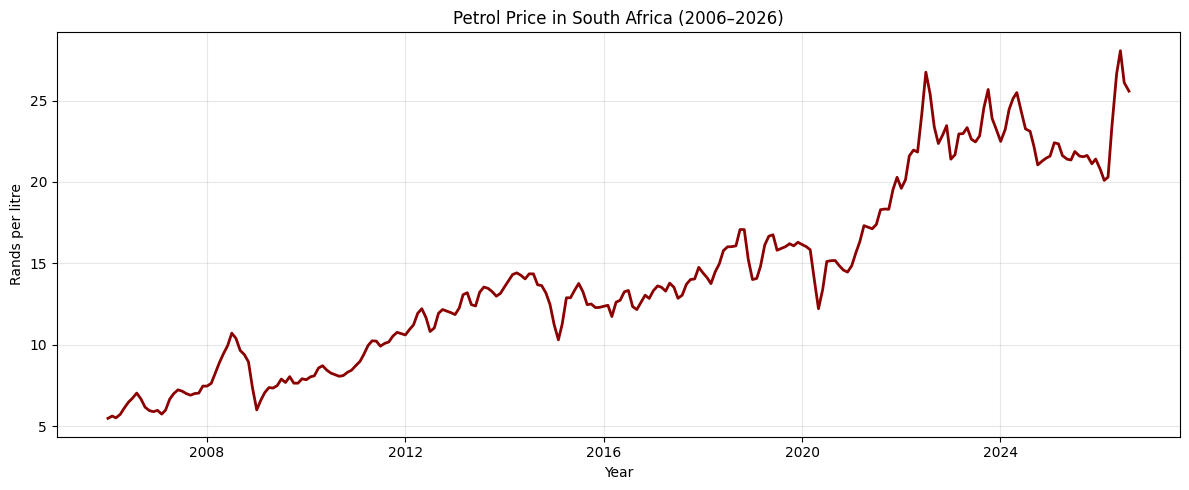

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df['date'], df['pump_price_rands'], color='darkred', linewidth=2)
plt.title('Petrol Price in South Africa (2006–2026)')
plt.ylabel('Rands per litre')
plt.xlabel('Year')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

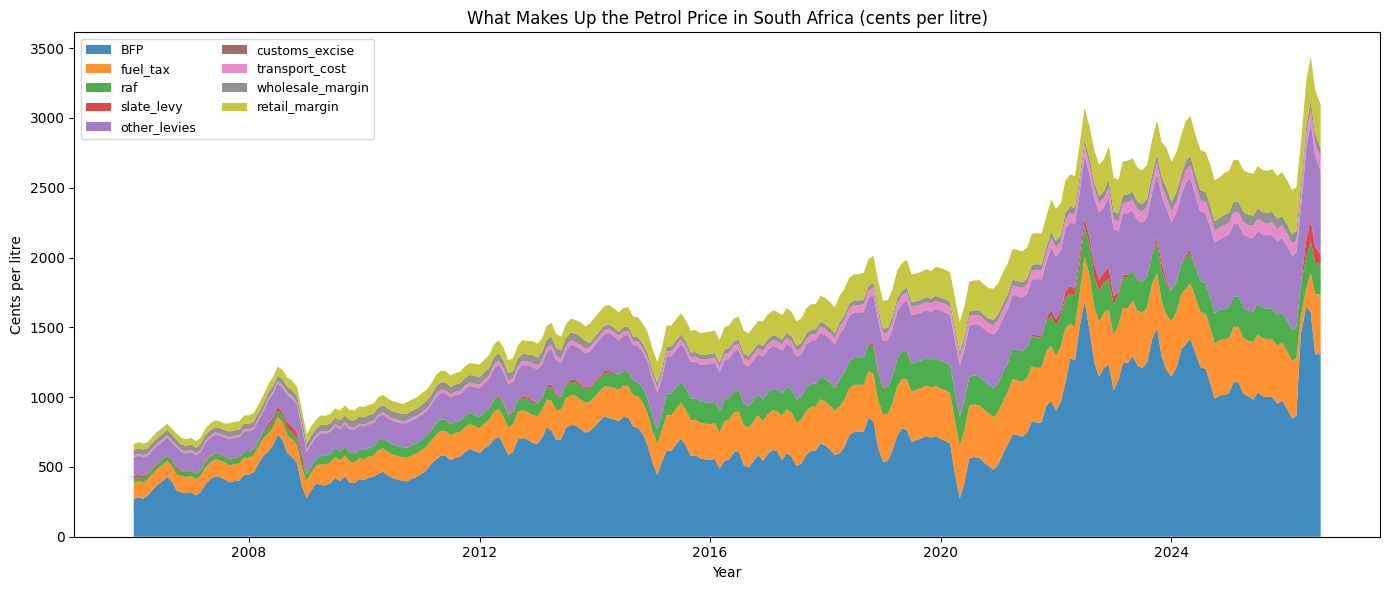

In [5]:
components = ['BFP', 'fuel_tax', 'raf', 'slate_levy', 'other_levies',
              'customs_excise', 'transport_cost', 'wholesale_margin', 'retail_margin']

plot_df = df.set_index('date')[components]

plt.figure(figsize=(14, 6))
plt.stackplot(plot_df.index,
              [plot_df[c].fillna(0) for c in components],
              labels=components, alpha=0.85)
plt.legend(loc='upper left', fontsize=9, ncol=2)
plt.title('What Makes Up the Petrol Price in South Africa (cents per litre)')
plt.ylabel('Cents per litre')
plt.xlabel('Year')
plt.tight_layout()
plt.show()

In [6]:
first = df.iloc[0]
last = df.iloc[-1]

print("First row:", first['date'], "— pump price:", first['pump_price_rands'], "rands")
print("Last row: ", last['date'], "— pump price:", last['pump_price_rands'], "rands")

# Total increase
total_increase = last['pump_price_rands'] - first['pump_price_rands']
print(f"\nTotal increase: R{total_increase:.2f}/litre")

# Component increases (in cents, so divide by 100 to compare with rands)
components = ['BFP', 'fuel_tax', 'raf', 'slate_levy', 'other_levies',
              'customs_excise', 'transport_cost', 'wholesale_margin', 'retail_margin']

print("\nIncrease per component (rands/litre):")
for c in components:
    increase_rands = (last[c] - first[c]) / 100
    pct = (increase_rands / total_increase) * 100
    print(f"  {c:20s}: +{increase_rands:.2f}  ({pct:.1f}% of total)")

# Group into BFP vs government taxes
bfp_increase = (last['BFP'] - first['BFP']) / 100
govt_increase = ((last['fuel_tax'] - first['fuel_tax']) +
                 (last['raf'] - first['raf']) +
                 (last['slate_levy'] - first['slate_levy'])) / 100

print(f"\nBFP increase:       R{bfp_increase:.2f}  ({bfp_increase/total_increase*100:.1f}%)")
print(f"Government levies:  R{govt_increase:.2f}  ({govt_increase/total_increase*100:.1f}%)")

First row: 2006-01-01 00:00:00 — pump price: 5.49 rands
Last row:  2026-08-05 00:00:00 — pump price: 25.58 rands

Total increase: R20.09/litre

Increase per component (rands/litre):
  BFP                 : +10.39  (51.7% of total)
  fuel_tax            : +3.13  (15.6% of total)
  raf                 : +1.93  (9.6% of total)
  slate_levy          : +0.46  (2.3% of total)
  other_levies        : +4.65  (23.1% of total)
  customs_excise      : +0.00  (0.0% of total)
  transport_cost      : +0.78  (3.9% of total)
  wholesale_margin    : +0.28  (1.4% of total)
  retail_margin       : +2.71  (13.5% of total)

BFP increase:       R10.39  (51.7%)
Government levies:  R5.52  (27.5%)


Between 2006 and 2026, the petrol price in South Africa rose from R5.49 to R25.58 per litre. Of that increase, 51.7% came from the Basic Fuel Price and 27.5% from government taxes and levies.

In [7]:
print(f"Latest petrol price: R{df['pump_price_rands'].iloc[-1]:.2f}")
print(f"Latest date: {df['date'].iloc[-1].date()}")

Latest petrol price: R25.58
Latest date: 2026-08-05


In [9]:
print(df[['date', 'pump_price_rands']].tail(3))
print("Latest:", df['date'].iloc[-1].date(), "→ R", df['pump_price_rands'].iloc[-1])

          date  pump_price_rands
244 2026-06-03             28.06
245 2026-07-01             26.10
246 2026-08-05             25.58
Latest: 2026-08-05 → R 25.58


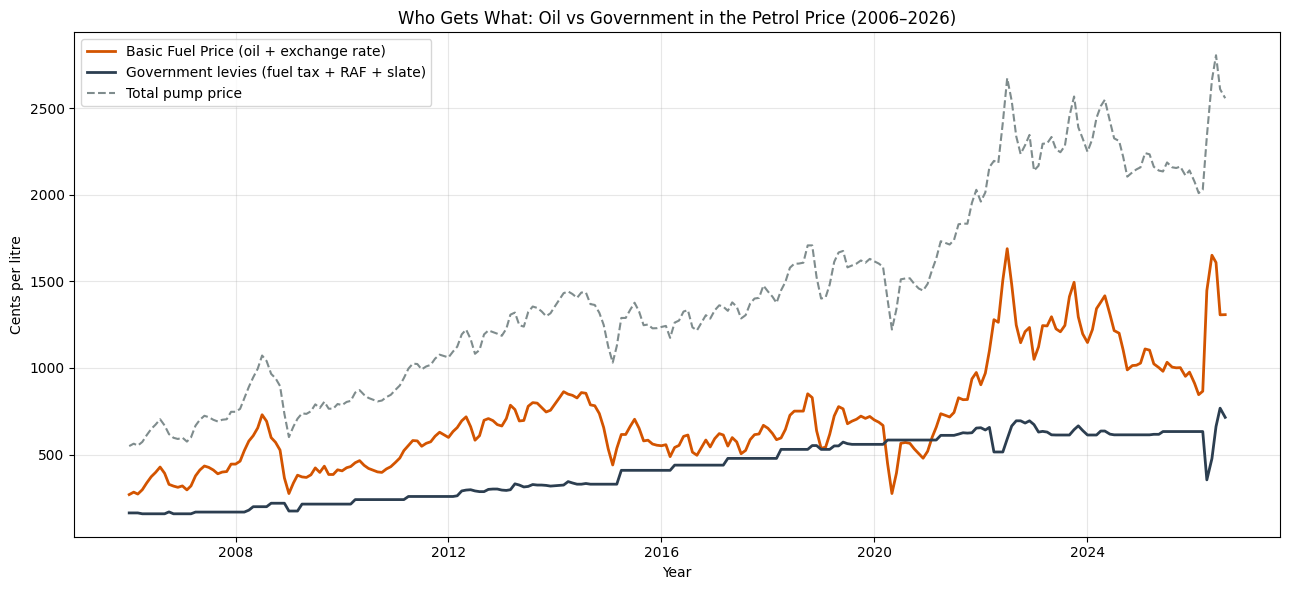

In [10]:
import matplotlib.pyplot as plt

# Government's cut = fuel tax + RAF + slate levy (in cents)
govt = df['fuel_tax'] + df['raf'] + df['slate_levy']

plt.figure(figsize=(13, 6))
plt.plot(df['date'], df['BFP'], label='Basic Fuel Price (oil + exchange rate)',
         color='#d35400', linewidth=2)
plt.plot(df['date'], govt, label='Government levies (fuel tax + RAF + slate)',
         color='#2c3e50', linewidth=2)
plt.plot(df['date'], df['pump_price_cents'], label='Total pump price',
         color='#7f8c8d', linewidth=1.5, linestyle='--')

plt.title('Who Gets What: Oil vs Government in the Petrol Price (2006–2026)')
plt.ylabel('Cents per litre')
plt.xlabel('Year')
plt.legend(loc='upper left', fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

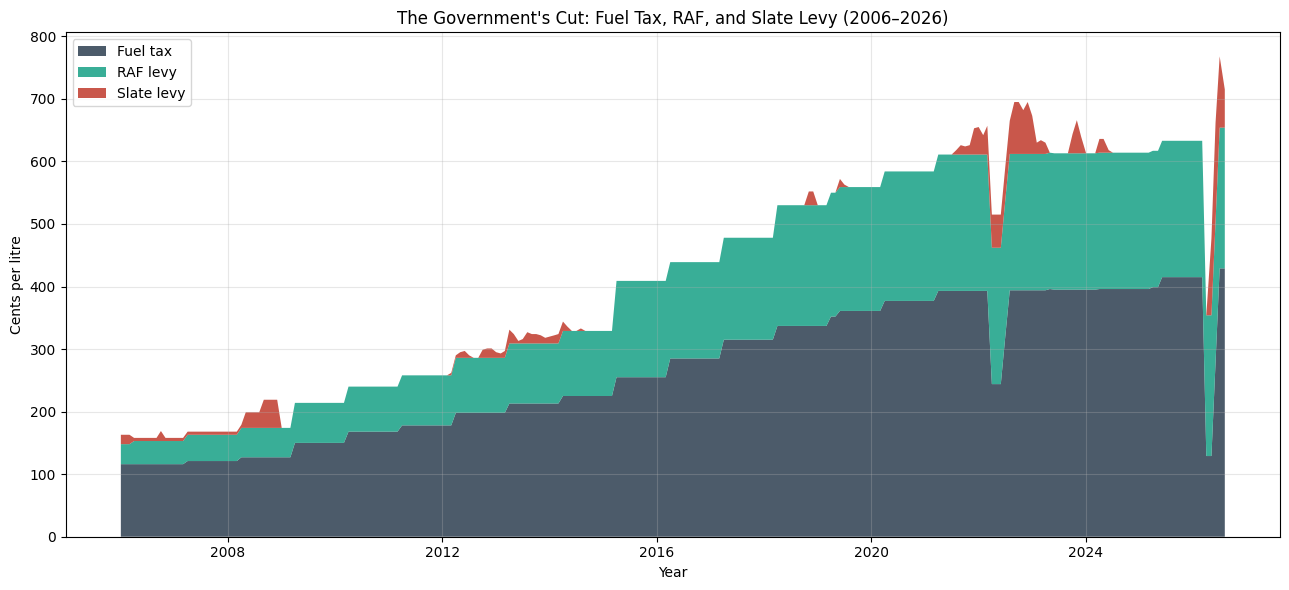

In [11]:
plt.figure(figsize=(13, 6))
plt.stackplot(df['date'],
              df['fuel_tax'], df['raf'], df['slate_levy'],
              labels=['Fuel tax', 'RAF levy', 'Slate levy'],
              colors=['#2c3e50', '#16a085', '#c0392b'],
              alpha=0.85)
plt.title("The Government's Cut: Fuel Tax, RAF, and Slate Levy (2006–2026)")
plt.ylabel('Cents per litre')
plt.xlabel('Year')
plt.legend(loc='upper left', fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# Cross-check: does the sum of components equal the pump price?
components = ['BFP', 'fuel_tax', 'raf', 'slate_levy', 'other_levies',
              'customs_excise', 'transport_cost', 'wholesale_margin', 'retail_margin']

df['sum_of_components'] = df[components].sum(axis=1)
df['diff_cents'] = df['pump_price_cents'] - df['sum_of_components']

print(df[['date', 'pump_price_cents', 'sum_of_components', 'diff_cents']].tail(5))
print("\nMax discrepancy (cents):", df['diff_cents'].abs().max())

          date  pump_price_cents  sum_of_components  diff_cents
242 2026-04-01              2336            2813.13     -477.13
243 2026-05-06              2663            3262.83     -599.83
244 2026-06-03              2806            3440.87     -634.87
245 2026-07-01              2610            3201.07     -591.07
246 2026-08-05              2558            3096.51     -538.51

Max discrepancy (cents): 634.8699999999999


In [13]:
# Check: do the individual components, excluding potential double-counts,
# add up correctly?

# First, list every numeric column and look at a sample row
sample = df.iloc[-5]  # a recent row
for col in df.columns:
    print(f"{col:25s}: {sample[col]}")

BFP                      : 1447.0
raf                      : 225.0
date                     : 2026-04-01 00:00:00
dsml                     : nan
year                     : 2026
iirtc                    : nan
month                    : Apr
fuel_tax                 : 129.0
slate_levy               : 0.0
other_levies             : 535.13
crude_oil_usd            : 93.67
delivery_cost            : 0.0
exchange_rate            : 16.64
retail_margin            : 315.0
customs_excise           : 4.0
transport_cost           : 91.0
pump_price_cents         : 2336
pump_price_rands         : 23.36
wholesale_margin         : 67.0
secondary_storage        : 39.0
equilisation_fund_levy   : 0.0
secondary_distribution   : 19.0
petroleum_products_levy  : 0.0
sum_of_components        : 2813.13
diff_cents               : -477.1300000000001


In [14]:
# Does other_levies equal the sum of the other levy-like columns?
levy_like = ['customs_excise', 'transport_cost', 'secondary_storage',
             'secondary_distribution', 'slate_levy', 'raf']

sample = df.iloc[-5]
print("Sample other_levies value:      ", sample['other_levies'])
print("Sum of individual levy columns: ", sample[levy_like].sum())
print()

# Check across the whole dataset
df['levy_check'] = df[levy_like].sum(axis=1)
df['other_vs_individual'] = df['other_levies'] - df['levy_check']
print(df[['date', 'other_levies', 'levy_check', 'other_vs_individual']].tail(10))

Sample other_levies value:       535.13
Sum of individual levy columns:  378.0

          date  other_levies  levy_check  other_vs_individual
237 2025-11-05        527.53       366.0               161.53
238 2025-12-03        531.13       367.0               164.13
239 2026-01-07        531.13       367.0               164.13
240 2026-02-04        531.13       367.0               164.13
241 2026-03-04        531.13       367.0               164.13
242 2026-04-01        535.13       378.0               157.13
243 2026-05-06        657.83       501.0               156.83
244 2026-06-03        692.87       536.0               156.87
245 2026-07-01        649.07       492.0               157.07
246 2026-08-05        596.51       439.0               157.51


In [15]:
# Formula 1: assume other_levies is a standalone add-on
f1 = ['BFP', 'fuel_tax', 'raf', 'slate_levy', 'other_levies',
      'wholesale_margin', 'retail_margin']

# Formula 2: assume the individual levy columns are the truth, ignore other_levies
f2 = ['BFP', 'fuel_tax', 'raf', 'slate_levy',
      'customs_excise', 'transport_cost', 'secondary_storage',
      'secondary_distribution', 'wholesale_margin', 'retail_margin']

for name, cols in [('Formula 1 (uses other_levies)', f1),
                   ('Formula 2 (uses individual levies)', f2)]:
    df['test_sum'] = df[cols].sum(axis=1)
    df['test_diff'] = df['pump_price_cents'] - df['test_sum']
    print(f"\n{name}")
    print(f"  Columns: {cols}")
    print(f"  Mean diff: {df['test_diff'].mean():.2f} cents")
    print(f"  Max abs diff: {df['test_diff'].abs().max():.2f} cents")
    print(f"  Std of diff: {df['test_diff'].std():.2f} cents")


Formula 1 (uses other_levies)
  Columns: ['BFP', 'fuel_tax', 'raf', 'slate_levy', 'other_levies', 'wholesale_margin', 'retail_margin']
  Mean diff: -216.57 cents
  Max abs diff: 539.87 cents
  Std of diff: 95.07 cents

Formula 2 (uses individual levies)
  Columns: ['BFP', 'fuel_tax', 'raf', 'slate_levy', 'customs_excise', 'transport_cost', 'secondary_storage', 'secondary_distribution', 'wholesale_margin', 'retail_margin']
  Mean diff: 14.88 cents
  Max abs diff: 46.00 cents
  Std of diff: 12.62 cents


In [16]:
# Formula 3: Formula 2 + the small extra columns
f3 = ['BFP', 'fuel_tax', 'raf', 'slate_levy',
      'customs_excise', 'transport_cost', 'secondary_storage',
      'secondary_distribution', 'wholesale_margin', 'retail_margin',
      'delivery_cost', 'equilisation_fund_levy', 'petroleum_products_levy']

df['test_sum'] = df[f3].sum(axis=1)
df['test_diff'] = df['pump_price_cents'] - df['test_sum']
print("Formula 3 (adds delivery_cost, equilisation_fund_levy, petroleum_products_levy)")
print(f"  Mean diff: {df['test_diff'].mean():.2f}")
print(f"  Max abs diff: {df['test_diff'].abs().max():.2f}")
print(f"  Std: {df['test_diff'].std():.2f}")

# Where are the biggest discrepancies? Which dates?
df['abs_diff'] = df['test_diff'].abs()
print("\nTop 10 rows with worst fit:")
print(df.nlargest(10, 'abs_diff')[['date', 'pump_price_cents', 'test_sum', 'test_diff']])

Formula 3 (adds delivery_cost, equilisation_fund_levy, petroleum_products_levy)
  Mean diff: 8.37
  Max abs diff: 27.00
  Std: 5.06

Top 10 rows with worst fit:
          date  pump_price_cents  test_sum  test_diff
142 2017-12-01              1476    1449.0       27.0
181 2021-03-01              1632    1616.0       16.0
187 2021-09-01              1834    1818.0       16.0
188 2021-10-01              1833    1817.0       16.0
189 2021-11-01              1954    1938.0       16.0
41  2009-06-01               750     737.0       13.0
42  2009-07-01               790     777.0       13.0
45  2009-10-01               765     752.0       13.0
46  2009-11-01               765     752.0       13.0
47  2009-12-01               792     779.0       13.0


In [17]:
components = [
    'BFP',                          # Basic Fuel Price (oil + freight + insurance)
    'fuel_tax',                     # General fuel levy
    'raf',                          # Road Accident Fund levy
    'slate_levy',                   # Slate levy (debt recovery)
    'customs_excise',               # Customs and excise
    'transport_cost',               # Transport to depot
    'secondary_storage',            # Storage
    'secondary_distribution',       # Distribution
    'wholesale_margin',             # Wholesaler cut
    'retail_margin',                # Petrol station cut
    'delivery_cost',                # Delivery
    'equilisation_fund_levy',       # Equalisation fund
    'petroleum_products_levy',      # Petroleum products levy
]

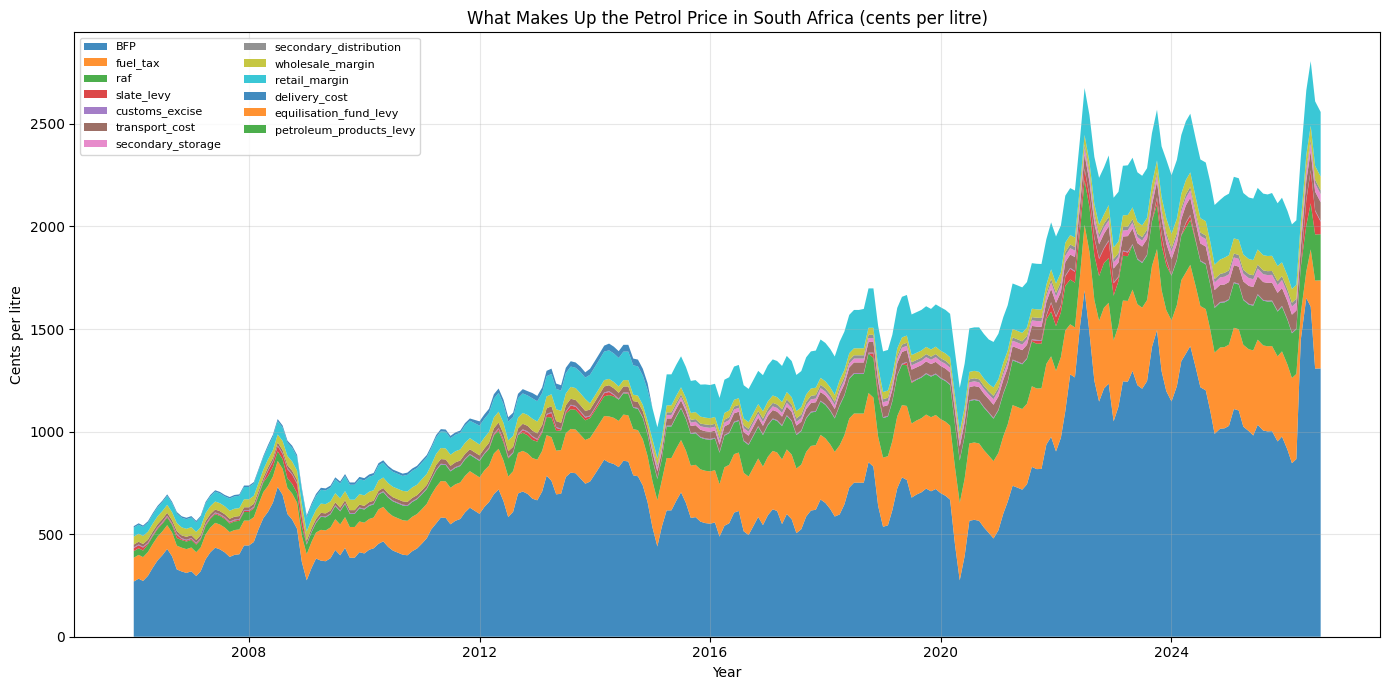

In [18]:
import matplotlib.pyplot as plt

df['sum_components'] = df[components].sum(axis=1)

plt.figure(figsize=(14, 7))
plt.stackplot(df['date'],
              [df[c].fillna(0) for c in components],
              labels=components, alpha=0.85)
plt.legend(loc='upper left', fontsize=8, ncol=2)
plt.title('What Makes Up the Petrol Price in South Africa (cents per litre)')
plt.ylabel('Cents per litre')
plt.xlabel('Year')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Methodology Note
The pump price was decomposed into 13 components sourced from DataDesk (DS0150).
Validated the sum of components against the reported pump price: mean discrepancy
of +8.37 cents/litre (max 27 cents,in December 2017). The remaining gap is likely an unpublished
levy or rounding in the source data.

# Petrol Price in South Africa: A 20-Year Breakdown

## What This Project Does
Analyzes the pump price of petrol in South Africa from 2006 to 2026,
decomposing each litre into its components: Basic Fuel Price (BFP),
fuel tax, RAF levy, slate levy, and margins.

## Key Findings
- Petrol rose from **R5.49** (Jan 2006) to **R25.58** (Aug 2026) per litre
- **51.7%** of the increase came from the Basic Fuel Price (crude oil + exchange rate)
- **27.5%** came from government taxes and levies (fuel tax + RAF + slate levy)
- **13.5%** came from the retail margin
- The 2008 oil spike and 2020 COVID crash are both visible in the chart

## Data Source
DataDesk (DS0150) — Petrol price in South Africa since 2006